⬇️ В этом юните мы посмотрим на результат работы AutoML на наборе данных классификации грибов. 

Набор данных содержит 23 категориальных объекта и более 8 000 наблюдений. 
Данные делятся на две категории: съедобные и ядовитые. 
Классы распределены довольно равномерно: 52 % наблюдений приходится на съедобный класс. 
В данных нет пропущенных наблюдений. 
Сначала вам нужно будет установить и импортировать модуль Python H2O и класс H2OAutoML, как и любую другую библиотеку, и инициализировать H2O.

In [3]:
#!pip install h2o
import h2o
from sklearn.preprocessing import LabelEncoder 
from h2o.automl import H2OAutoML
h2o.init()

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
import transformers
from transformers import AutoModel, BertTokenizerFast

# Автоматически выбираем устройство
# Automatically select device

import torch

Checking whether there is an H2O instance running at http://localhost:54321. connected.


H2O_cluster_uptime:,5 mins 29 secs
H2O_cluster_timezone:,Europe/Moscow
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.12
H2O_cluster_version_age:,3 months and 2 days
H2O_cluster_name:,H2O_from_python_ekash_al6znu
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,15.93 Gb
H2O_cluster_total_cores:,36
H2O_cluster_allowed_cores:,36
H2O_cluster_status:,"locked, healthy"



+------------------------------------------------------------------+
| You are running the community edition of H2O-3 OSS.              |
|                                                                  |
| For commercial use, H2O-3 Secure is now recommended.             |
| This includes production support, CVE fixes, multi-node scaling, |
| model artifact extraction, and more.                             |
| See h2o.ai/h2o-3/oss-vs-secure for additional details.           |
| Contact enterprise@h2o.ai to upgrade.                            |
+------------------------------------------------------------------+


Затем нам нужно загрузить данные. Это можно сделать либо прямо в «H2OFrame» (закомментированный пример), либо обычным способом, чтобы мы могли закодировать целевую переменную, а затем преобразовать их в H2OFrame. 

Как и многие функции и объекты в H2O, H2OFrame схож с Pandas DataFrame, но имеет свои небольшие отличия и синтаксис. Например, H2O может самостоятельно обрабатывать категориальные признаки, поэтому выполнять этот шаг отдельно не требуется.

In [4]:
from pathlib import Path

path = Path.cwd() / '../data'

df = pd.read_csv(path/"mushrooms.csv")
# df = h2o.import_file("mushrooms.csv", header =1)

labelEncoder = LabelEncoder()
for column in df.columns:
    df[column] = labelEncoder.fit_transform(df[column])
df = h2o.H2OFrame(df)
df = df.asfactor()

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%


In [7]:
display(df.head())
print(df.types)
display(df.describe())

class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,stalk-root,stalk-surface-above-ring,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
1,5,2,4,1,6,1,0,1,4,0,3,2,2,7,7,0,2,1,4,2,3,5
0,5,2,9,1,0,1,0,0,4,0,2,2,2,7,7,0,2,1,4,3,2,1
0,0,2,8,1,3,1,0,0,5,0,2,2,2,7,7,0,2,1,4,3,2,3
1,5,3,8,1,6,1,0,1,5,0,3,2,2,7,7,0,2,1,4,2,3,5
0,5,2,3,0,5,1,1,0,4,1,3,2,2,7,7,0,2,1,0,3,0,1
0,5,3,9,1,0,1,0,0,5,0,2,2,2,7,7,0,2,1,4,2,2,1
0,0,2,8,1,0,1,0,0,2,0,2,2,2,7,7,0,2,1,4,2,2,3
0,0,3,8,1,3,1,0,0,5,0,2,2,2,7,7,0,2,1,4,3,3,3
1,5,3,8,1,6,1,0,1,7,0,3,2,2,7,7,0,2,1,4,2,4,1
0,0,2,9,1,0,1,0,0,2,0,2,2,2,7,7,0,2,1,4,2,3,3


{'class': 'enum', 'cap-shape': 'enum', 'cap-surface': 'enum', 'cap-color': 'enum', 'bruises': 'enum', 'odor': 'enum', 'gill-attachment': 'enum', 'gill-spacing': 'enum', 'gill-size': 'enum', 'gill-color': 'enum', 'stalk-shape': 'enum', 'stalk-root': 'enum', 'stalk-surface-above-ring': 'enum', 'stalk-surface-below-ring': 'enum', 'stalk-color-above-ring': 'enum', 'stalk-color-below-ring': 'enum', 'veil-type': 'enum', 'veil-color': 'enum', 'ring-number': 'enum', 'ring-type': 'enum', 'spore-print-color': 'enum', 'population': 'enum', 'habitat': 'enum'}


Rows:8124
Cols:23

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,stalk-root,stalk-surface-above-ring,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
type,enum,enum,enum,enum,enum,enum,enum,enum,enum,enum,enum,enum,enum,enum,enum,enum,enum,enum,enum,enum,enum,enum,enum
mins,,,,,,,,,,,,,,,,,,,,,,,
mean,,,,,,,,,,,,,,,,,,,,,,,
maxs,,,,,,,,,,,,,,,,,,,,,,,
sigma,,,,,,,,,,,,,,,,,,,,,,,
zeros,,,,,,,,,,,,,,,,,,,,,,,
missing,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
0,1,5,2,4,1,6,1,0,1,4,0,3,2,2,7,7,0,2,1,4,2,3,5
1,0,5,2,9,1,0,1,0,0,4,0,2,2,2,7,7,0,2,1,4,3,2,1
2,0,0,2,8,1,3,1,0,0,5,0,2,2,2,7,7,0,2,1,4,3,2,3


None

На этом этапе при создании MVP есть два пути:

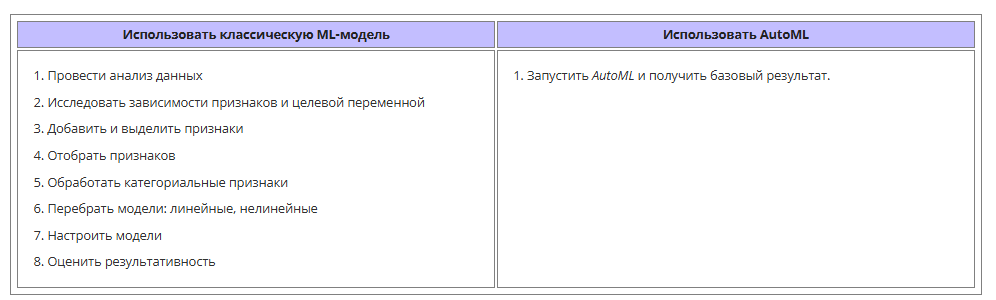
Получается, с использованием AutoML мы не будем проделывать эти шаги и сразу перейдём к обучению!

Подобно функциям в sklearn, мы можем создать разбиение на train и test, чтобы можно было проверить производительность модели на неизвестном наборе данных. 

In [8]:
# Разделяем данные на Train/Test/Validation. Train размером 70%, test и validation по 15% 
train_df, test_df = df.split_frame(ratios=[.7])

Затем нам нужно получить имена столбцов, чтобы передать их функции. 

Для AutoML необходимо указать несколько обязательных параметров: x, y и training_frame. Здесь вы также можете настроить значения max_runtime_sec и max_models. 

Max_runtime_sec — обязательный параметр, а max_model — необязательный. 
По умолчанию все непереданные параметры принимают значение NULL. 
Параметр x — это вектор признаков из training_frame. Если вы не хотите использовать все признаки из переданного кадра, вы можете установить его, передав его в x.
На этих данных будем использовать все признаки (кроме таргета) и установим max_runtime_sec на 10 минут (по умолчанию некоторые из моделей могут занять много времени). Запустим AutoML:

In [9]:
y = "class"
train_columns = train_df.columns
train_columns.remove(y)

aml_model = H2OAutoML(max_runtime_secs=500, seed = 1)
aml_model.train(x = train_columns, y = y, training_frame = train_df)

AutoML progress: |█
14:37:46.43: AutoML: XGBoost is not available; skipping it.
14:37:46.97: _train param, Dropping bad and constant columns: [veil-type]
14:37:48.496: _train param, Dropping bad and constant columns: [veil-type]

████
14:38:03.76: _train param, Dropping unused columns: [veil-type]
14:38:04.345: _train param, Dropping bad and constant columns: [veil-type]
14:38:05.367: _train param, Dropping bad and constant columns: [veil-type]

██
14:38:14.306: _train param, Dropping bad and constant columns: [veil-type]

██
14:38:23.495: _train param, Dropping bad and constant columns: [veil-type]

██
14:38:32.776: _train param, Dropping unused columns: [veil-type]
14:38:33.662: _train param, Dropping unused columns: [veil-type]

█
14:38:35.34: _train param, Dropping bad and constant columns: [veil-type]
14:38:35.839: _train param, Dropping bad and constant columns: [veil-type]

█
14:38:42.748: _train param, Dropping bad and constant columns: [veil-type]

██
14:38:44.188: _train para

Model Details
=============
H2OGradientBoostingEstimator : Gradient Boosting Machine
Model Key: GBM_grid_1_AutoML_1_20261113_143745_model_17


Model Summary: 
    number_of_trees    number_of_internal_trees    model_size_in_bytes    min_depth    max_depth    mean_depth    min_leaves    max_leaves    mean_leaves
--  -----------------  --------------------------  ---------------------  -----------  -----------  ------------  ------------  ------------  -------------
    658                658                         155922                 4            4            4             5             16            14.1717

ModelMetricsBinomial: gbm
** Reported on train data. **

MSE: 1.135992750580092e-33
RMSE: 3.370449154905162e-17
LogLoss: 2.1704482240882796e-18
Mean Per-Class Error: 0.0
AUC: 1.0
AUCPR: 1.0
Gini: 1.0

Confusion Matrix (Act/Pred) for max f1 @ threshold = 1.0
       0     1     Error    Rate
-----  ----  ----  -------  ------------
0      2957  0     0        (0.0/2957.0)
1      0     2772  0        (0.0/2772.0)
Total  2957  2772  0        (0.0/5729.0)

Maximum Metrics: Maximum metrics at their respective thresholds
metric                       threshold    value    idx
---------------------------  -----------  -------  -----
max f1                       1            1        0
max f2                       1            1        0
max f0point5                 1            1        0
max accuracy                 1            1        0
max precision                1            1        0
max recall                   1            1        0
max specificity              1            1        0
max absolute_mcc             1            1        0
max min_per_class_accuracy   1            1        0
max mean_per_class_accuracy  1            1        0
max tns                      1            2957     0
max fns                      1            0        0
max fps                      1e-19        2957     399
max tps                      1            2772     0
max tnr                      1            1        0
max fnr                      1            0        0
max fpr                      1e-19        1        399
max tpr                      1            1        0

Gains/Lift Table: Avg response rate: 48,39 %, avg score: 48,39 %
group    cumulative_data_fraction    lower_threshold    lift      cumulative_lift    response_rate    score        cumulative_response_rate    cumulative_score    capture_rate    cumulative_capture_rate    gain      cumulative_gain    kolmogorov_smirnov
-------  --------------------------  -----------------  --------  -----------------  ---------------  -----------  --------------------------  ------------------  --------------  -------------------------  --------  -----------------  --------------------
1        0.478443                    1                  2.06674   2.06674            1                1            1                           1                   0.988817        0.988817                   106.674   106.674            0.988817
2        0.500087                    2.25554e-17        0.516685  1.99965            0.25             0.25         0.967539                    0.967539            0.0111833       1                          -48.3315  99.9651            0.968549
3        0.59993                     3.65433e-18        0         1.66686            0                7.30291e-18  0.806517                    0.806517            0               1                          -100      66.6861            0.77511
4        0.699948                    2.27951e-18        0         1.42868            0                2.87882e-18  0.691272                    0.691272            0               1                          -100      42.8678            0.581332
5        0.799965                    1.60267e-18        0         1.25005            0                1.90199e-18  0.604844                    0.604844            0               1                          -100      25.0055            0.38

После запуска и обучения H2OAutoML вы можете посмотреть, какие модели в нашем случае сработали лучше всего, и выбрать их для дальнейшего исследования.

In [13]:
leaderboard = aml_model.leaderboard
leaderboard.head()

model_id,auc,logloss,aucpr,mean_per_class_error,rmse,mse
GBM_grid_1_AutoML_1_20261113_143745_model_17,1,8.32706e-09,1,0,6.29419e-07,3.96168e-13
StackedEnsemble_BestOfFamily_1_AutoML_1_20261113_143745,1,0.000848363,1,0,0.000860146,7.39851e-07
GBM_grid_1_AutoML_1_20261113_143745_model_10,1,2.86422e-17,1,0,1.46276e-15,2.13967e-30
GBM_grid_1_AutoML_1_20261113_143745_model_7,1,1.72473e-18,1,0,5.0022e-17,2.5022e-33
GBM_1_AutoML_1_20261113_143745,1,1.38613e-09,1,0,7.50097e-08,5.62646e-15
DeepLearning_grid_1_AutoML_1_20261113_143745_model_2,1,8.88211e-05,1,0,0.00138543,1.91941e-06
StackedEnsemble_AllModels_5_AutoML_1_20261113_143745,1,0.00325705,1,0,0.00325743,1.06109e-05
GBM_grid_1_AutoML_1_20261113_143745_model_14,1,1.5292e-16,1,0,8.54045e-15,7.29393e-29
DeepLearning_grid_1_AutoML_1_20261113_143745_model_6,1,1.79096e-05,1,0,0.000822035,6.75741e-07
GBM_5_AutoML_1_20261113_143745,1,8.63522e-12,1,0,6.52215e-10,4.25384e-19


In [11]:
prediction = aml_model.predict(test_df)

gbm prediction progress: |███████████████████████████████████████████████████████| (done) 100%


In [12]:
print(prediction.head())

  predict    p0           p1
        0     1  2.72239e-18
        0     1  4.85148e-19
        0     1  5.26371e-19
        1     0  1
        1     0  1
        0     1  1.44143e-18
        0     1  6.03721e-18
        0     1  4.85835e-19
        0     1  1.39425e-17
        0     1  8.09907e-18
[10 rows x 3 columns]

